# Notebook 4 — Breakout Strategy

## Strategy Overview

Breakout strategies enter positions when price moves decisively beyond a recent consolidation range, interpreting the breakout as the start of a new directional move. The underlying hypothesis is that **support and resistance levels represent supply/demand imbalances** — once breached with sufficient force, prices tend to continue in the breakout direction.

### Mathematical Foundation

We use a **Donchian Channel breakout** (Donchian 1960, later popularised by the Turtle Traders):

$$\text{Upper Channel}_t = \max_{i=1}^{N} H_{t-i}$$
$$\text{Lower Channel}_t = \min_{i=1}^{N} L_{t-i}$$

where $H$ and $L$ are daily high and low prices, and $N$ is the channel period (default 20 days).

**Entry signal** (bullish breakout):
$$C_t > \text{Upper Channel}_{t-1}$$

where we use yesterday's channel (computed from data strictly before today) to avoid look-ahead bias.

**Volume confirmation**: A breakout is only accepted if the accompanying trading volume exceeds its recent moving average:
$$V_t > \text{SMA}(V, 20)_{t-1}$$

**ATR-based volatility filter**: We require the channel width to exceed a minimum multiple of ATR, ensuring we only trade meaningful breakouts, not noise:
$$\frac{\text{Upper} - \text{Lower}}{2 \cdot \text{ATR}_{t,14}} > \text{threshold}$$

**Exit signal** uses a tighter 10-day Donchian channel:
$$C_t < \text{Lower Channel}(10 \text{ days})_{t-1}$$

or an ATR-based trailing stop:
$$C_t < \text{entry price} - 2 \times \text{ATR}_{t,14}$$

### Entry Conditions
1. Close breaks above the 20-day Donchian upper channel.
2. Volume > 20-day volume SMA (volume confirmation).
3. ADX(14) > 20 (trending market — breakouts fail more often in ranging markets).

### Exit Conditions (whichever triggers first)
1. Close falls below the 10-day Donchian lower channel.
2. ATR trailing stop: Close < (entry price − 2 × ATR).
3. 60-day holding period (maximum holding stop).

### Execution & Costs
- Next-day open execution.
- 10 bps round-trip transaction cost.
- Initial capital: ₹100,000.
- Long-only.

---

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

from modules.data_loader  import load_data, split_data
from modules.indicators   import donchian_channel, atr, sma, adx as compute_adx
from modules.backtester   import Backtester, benchmark_metrics, compute_metrics
from modules.performance  import (
    plot_equity_and_drawdown, plot_rolling_sharpe,
    plot_monthly_returns_heatmap, plot_return_distribution,
    metrics_to_dataframe, print_metrics_table
)

print('Libraries loaded.')

Libraries loaded.


## 1. Load Data

In [2]:
df = load_data()
train, val, test = split_data(df)
print(f'Dataset: {len(df):,} days')

Dataset: 2,478 days


## 2. Compute Indicators

In [3]:
# --- Parameters ---
DC_ENTRY_PERIOD = 20    # Donchian channel for entry
DC_EXIT_PERIOD  = 10    # Donchian channel for exit (tighter)
ATR_PERIOD      = 14    # ATR for trailing stop
ATR_STOP_MULT   = 2.0   # ATR stop multiplier
VOLUME_PERIOD   = 20    # Volume SMA period
ADX_PERIOD      = 14
ADX_THRESHOLD   = 20
MAX_HOLD_DAYS   = 60    # Maximum holding period (days)

close  = df['CLOSE']
high   = df['HIGH']
low    = df['LOW']
volume = df['SHARES_TRADED']

# Entry channel (20-day)
dc_entry = donchian_channel(high, low, DC_ENTRY_PERIOD)
# Exit channel (10-day)
dc_exit  = donchian_channel(high, low, DC_EXIT_PERIOD)
# ATR
atr_vals = atr(high, low, close, ATR_PERIOD)
# Volume SMA
vol_sma  = sma(volume.astype(float), VOLUME_PERIOD)
# ADX
adx_df   = compute_adx(high, low, close, ADX_PERIOD)
adx_vals = adx_df['adx']

print('Indicators computed.')
print(f'20-day Donchian upper (last): {dc_entry["upper"].iloc[-1]:.2f}')
print(f'20-day Donchian lower (last): {dc_entry["lower"].iloc[-1]:.2f}')
print(f'ATR(14) last: {atr_vals.iloc[-1]:.2f}')

Indicators computed.
20-day Donchian upper (last): 26236.40
20-day Donchian lower (last): 25693.25
ATR(14) last: 172.91


## 3. Generate Signal

We use a shifted (lagged) channel so that the entry/exit decision at close of day $t$ is based on the channel computed up to day $t-1$. This guarantees no look-ahead bias.

In [4]:
# Yesterday's channels (no look-ahead)
prev_dc_upper = dc_entry['upper'].shift(1)
prev_dc_lower_exit = dc_exit['lower'].shift(1)
prev_vol_sma  = vol_sma.shift(1)

signal = pd.Series(0, index=df.index)
in_pos       = False
days_held    = 0
entry_price  = None
atr_at_entry = None

for i, date in enumerate(df.index):
    if pd.isna(prev_dc_upper.iloc[i]) or pd.isna(atr_vals.iloc[i]):
        continue

    p   = close.iloc[i]
    v   = volume.iloc[i]
    adx = adx_vals.iloc[i]

    if not in_pos:
        # Entry: close breaks above 20-day Donchian upper with volume + ADX
        if (p > prev_dc_upper.iloc[i] and
            not pd.isna(prev_vol_sma.iloc[i]) and
            v > prev_vol_sma.iloc[i] and
            not pd.isna(adx) and adx > ADX_THRESHOLD):
            in_pos       = True
            entry_price  = p
            atr_at_entry = atr_vals.iloc[i]
            days_held    = 0
    else:
        days_held += 1
        atr_stop   = entry_price - ATR_STOP_MULT * atr_at_entry
        # Exit conditions
        exit_dc   = p < prev_dc_lower_exit.iloc[i] if not pd.isna(prev_dc_lower_exit.iloc[i]) else False
        exit_atr  = p < atr_stop
        exit_time = days_held >= MAX_HOLD_DAYS
        if exit_dc or exit_atr or exit_time:
            in_pos    = False
            entry_price = atr_at_entry = None
            days_held = 0

    signal.iloc[i] = 1 if in_pos else 0

exposure = signal.mean() * 100
n_entries = int(signal.diff().clip(lower=0).sum())
print(f'Market exposure   : {exposure:.1f}%')
print(f'Number of entries : {n_entries}')

Market exposure   : 28.3%
Number of entries : 28


## 4. Visualise Donchian Channels and Signals

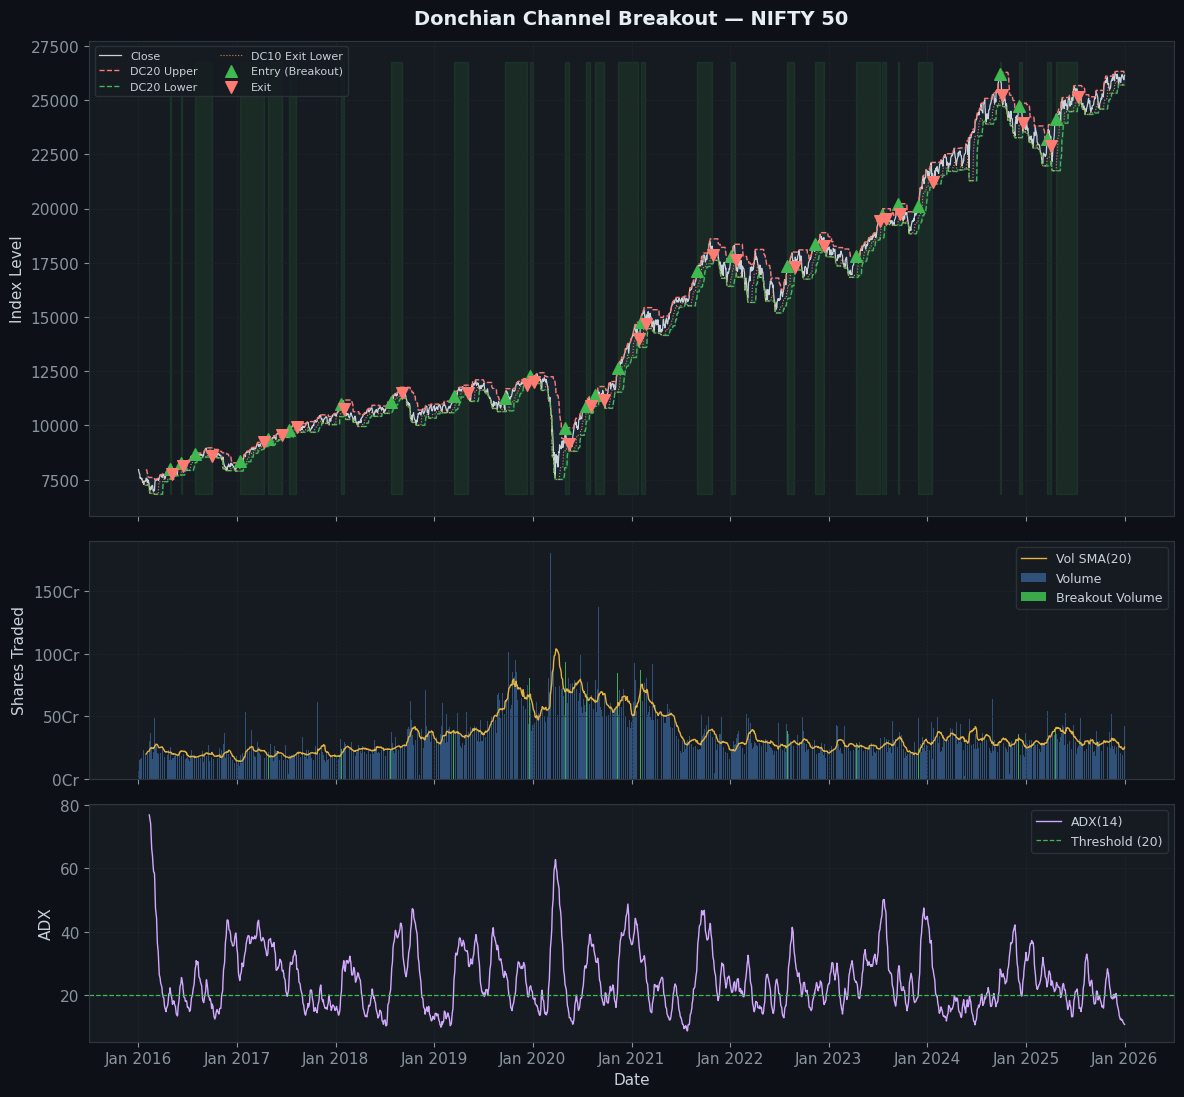

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 13), sharex=True,
                          gridspec_kw={'height_ratios': [3, 1.5, 1.5], 'hspace': 0.08})

# Panel 1: Price + Donchian channels
ax1 = axes[0]
ax1.plot(close.index, close.values, color='#c9d1d9', linewidth=0.9, label='Close', zorder=2)
ax1.plot(dc_entry['upper'].index, dc_entry['upper'].values,
         color='#ff7b72', linewidth=1.0, linestyle='--', label='DC20 Upper')
ax1.plot(dc_entry['lower'].index, dc_entry['lower'].values,
         color='#3fb950', linewidth=1.0, linestyle='--', label='DC20 Lower')
ax1.plot(dc_exit['lower'].index, dc_exit['lower'].values,
         color='#ffa657', linewidth=0.8, linestyle=':', alpha=0.8, label='DC10 Exit Lower')
ax1.fill_between(dc_entry['upper'].index,
                 dc_entry['upper'].values, dc_entry['lower'].values,
                 alpha=0.07, color='#58a6ff')

in_market = signal == 1
ax1.fill_between(signal.index, close.min() * 0.98, close.max() * 1.02,
                 where=in_market.values, alpha=0.10, color='#3fb950')

entries = signal[(signal == 1) & (signal.shift(1) != 1)]
exits   = signal[(signal == 0) & (signal.shift(1) == 1)]
ax1.scatter(entries.index, close.loc[entries.index], marker='^',
            color='#3fb950', s=70, zorder=5, label='Entry (Breakout)')
ax1.scatter(exits.index, close.loc[exits.index], marker='v',
            color='#ff7b72', s=70, zorder=5, label='Exit')

ax1.set_title('Donchian Channel Breakout — NIFTY 50', fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel('Index Level')
ax1.legend(loc='upper left', fontsize=8, ncol=2)
ax1.grid(True)

# Panel 2: Volume with SMA
ax2 = axes[1]
ax2.bar(volume.index, volume.values, color='#58a6ff', alpha=0.4, width=1, label='Volume')
ax2.plot(vol_sma.index, vol_sma.values, color='#e3b341', linewidth=1.0, label='Vol SMA(20)')
# Highlight breakout volume bars
breakout_vol = entries.index
ax2.bar(breakout_vol, volume.loc[breakout_vol], color='#3fb950', alpha=0.9, width=2, label='Breakout Volume')
ax2.set_ylabel('Shares Traded')
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e7:.0f}Cr'))
ax2.legend(fontsize=9)
ax2.grid(True)

# Panel 3: ADX
ax3 = axes[2]
ax3.plot(adx_vals.index, adx_vals.values, color='#d2a8ff', linewidth=1.0, label='ADX(14)')
ax3.axhline(ADX_THRESHOLD, color='#3fb950', linewidth=0.9, linestyle='--',
            label=f'Threshold ({ADX_THRESHOLD})')
ax3.set_ylabel('ADX')
ax3.set_xlabel('Date')
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax3.xaxis.set_major_locator(mdates.YearLocator())
ax3.legend(fontsize=9)
ax3.grid(True)

plt.tight_layout()
plt.show()

## 5. Backtest

In [6]:
INITIAL_CAPITAL = 100_000
COST_BPS        = 10

bt     = Backtester(df, initial_capital=INITIAL_CAPITAL, cost_bps=COST_BPS)
result = bt.run(signal, params={
    'dc_entry': DC_ENTRY_PERIOD,
    'dc_exit':  DC_EXIT_PERIOD,
    'atr_stop': ATR_STOP_MULT,
    'max_hold': MAX_HOLD_DAYS,
})

bh_ret = df['CLOSE'].pct_change().fillna(0)
bh_eq  = INITIAL_CAPITAL * (1 + bh_ret).cumprod()

print(f'Strategy: ₹{result.portfolio_val.iloc[-1]:,.2f} | Benchmark: ₹{bh_eq.iloc[-1]:,.2f}')

Strategy: ₹119,343.65 | Benchmark: ₹328,342.25


## 6. Equity Curve and Drawdown

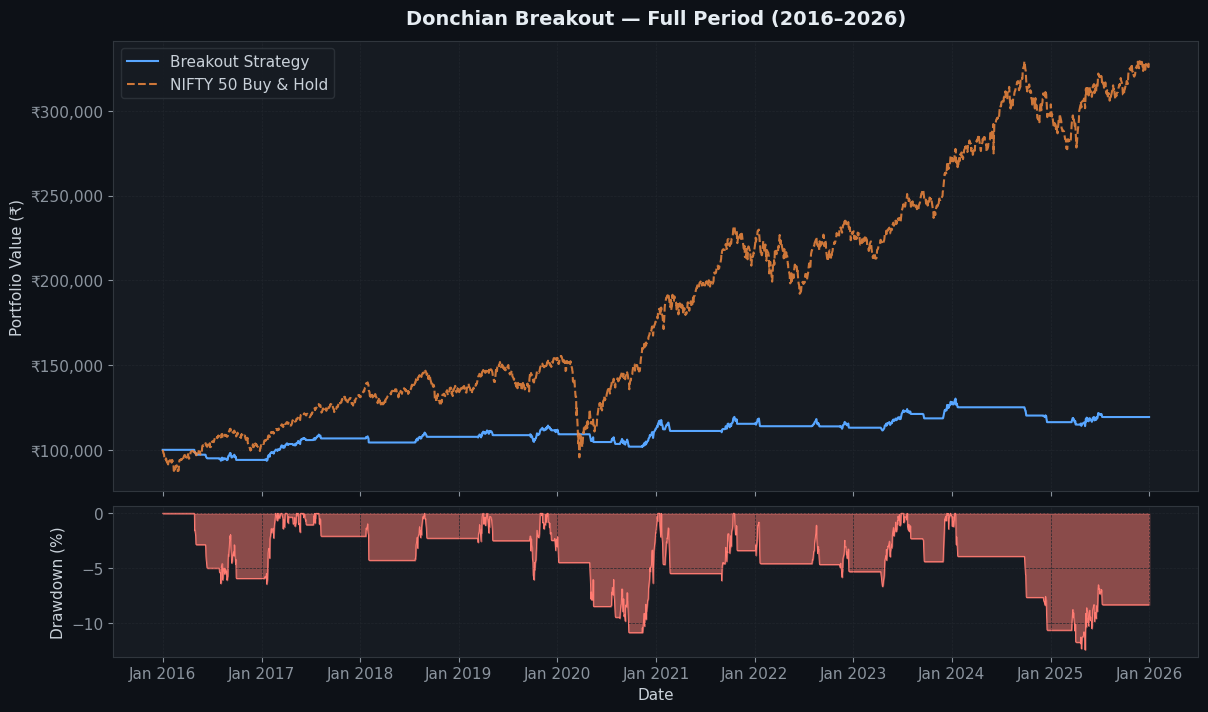

In [7]:
fig = plot_equity_and_drawdown(
    result.portfolio_val, result.returns, benchmark_equity=bh_eq,
    title='Donchian Breakout — Full Period (2016–2026)',
    strategy_label='Breakout Strategy'
)
plt.show()

## 7. Performance Metrics

In [8]:
bm_m = benchmark_metrics(df, initial_capital=INITIAL_CAPITAL)
print_metrics_table(result.metrics, 'Breakout vs NIFTY 50', benchmark_metrics=bm_m)
metrics_to_dataframe(result.metrics, bm_m, strategy_name='Breakout')


  Breakout vs NIFTY 50
Metric                               Strategy      Benchmark
------------------------------------------------------------
  Total Return (%)                     19.340        228.340
  CAGR (%)                              1.810         12.860
  Ann. Volatility (%)                   6.170         16.200
  Sharpe Ratio                         -0.698          0.440
  Sortino Ratio                        -0.949          0.601
  Calmar Ratio                          0.146          0.334
  Max Drawdown (%)                    -12.470        -38.440
  Avg DD Duration (days)               80.800         19.000
  Longest DD (days)                       487            314
  Win Rate (%)                         15.540         54.300
  Avg Win (%)                           0.532          0.681
  Avg Loss (%)                         -0.538         -0.694
  Profit Factor                         1.106          1.168
  VaR 95% (%)                          -0.565         -1.392


,Breakout,NIFTY 50 B&H
Total Return (%),19.340,228.340
CAGR (%),1.810,12.860
Ann. Volatility (%),6.170,16.200
Sharpe Ratio,-0.698,0.440
Sortino Ratio,-0.949,0.601
Calmar Ratio,0.146,0.334
Max Drawdown (%),-12.470,-38.440
Avg DD Duration (days),80.800,19.000
Longest DD (days),487.000,314.000
Win Rate (%),15.540,54.300


## 8. Rolling Sharpe

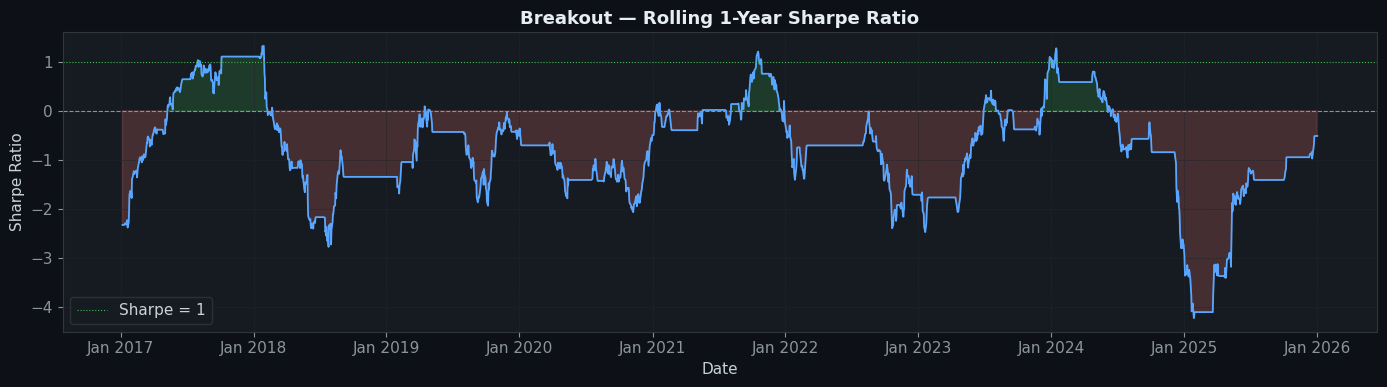

In [9]:
fig = plot_rolling_sharpe(result.returns, window=252,
                           title='Breakout — Rolling 1-Year Sharpe Ratio')
plt.show()

## 9. Monthly Returns Heatmap

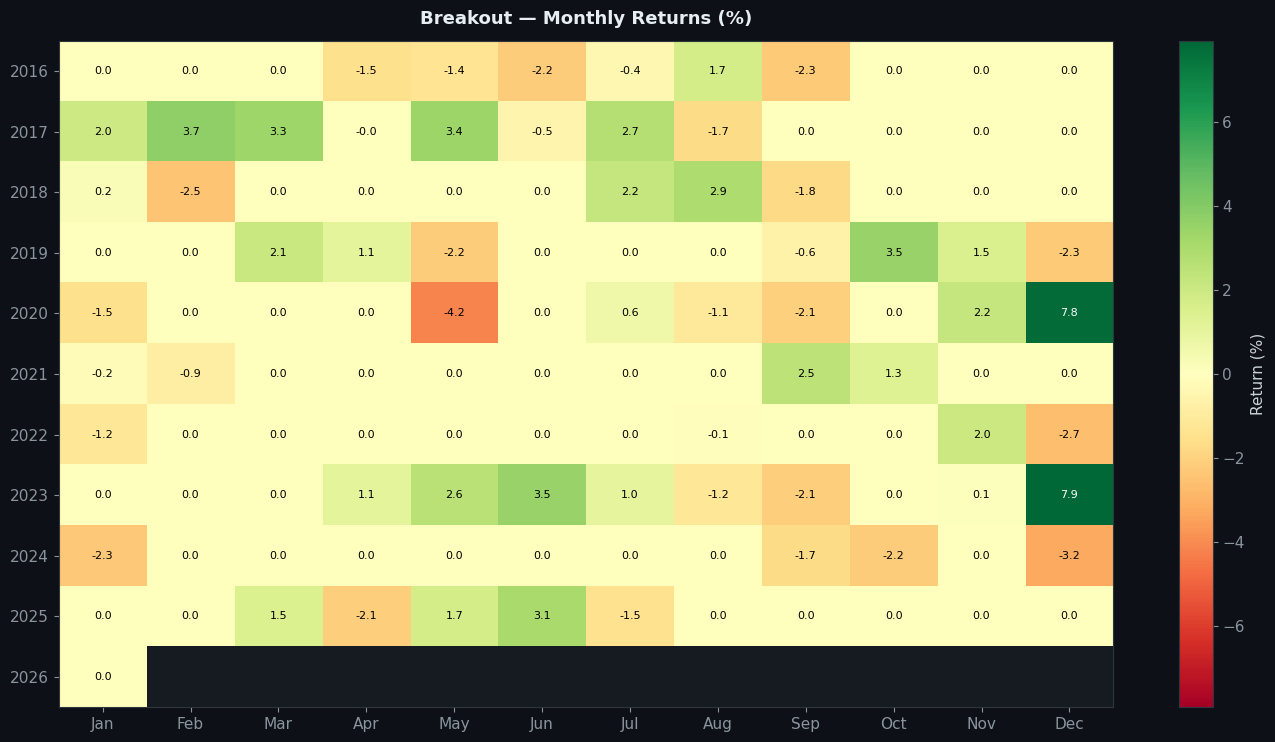

In [10]:
fig = plot_monthly_returns_heatmap(result.returns, title='Breakout — Monthly Returns (%)')
plt.show()

## 10. Return Distribution

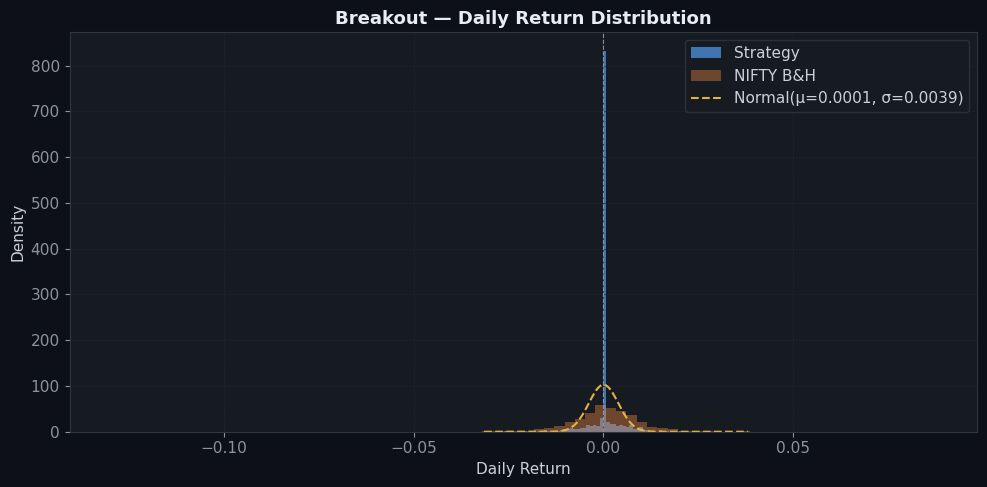

In [11]:
fig = plot_return_distribution(result.returns, benchmark_returns=bh_ret,
                                title='Breakout — Daily Return Distribution')
plt.show()

## 11. Sub-Period Analysis

In [12]:
subsets = {'Train (2016–2021)': train, 'Val (2022–mid-2023)': val, 'Test (mid-2023–2026)': test}
print(f'{'Period':<25} {'CAGR %':>8} {'Sharpe':>8} {'MaxDD %':>9} {'WinRate%':>10}')
print('-' * 65)
for name, subset in subsets.items():
    sub_ret = result.returns.reindex(subset.index)
    sub_eq  = result.portfolio_val.reindex(subset.index)
    if sub_ret.dropna().empty:
        continue
    sub_cap = sub_eq.dropna().iloc[0]
    m = compute_metrics(sub_ret, sub_eq, sub_cap, benchmark_close=subset['CLOSE'])
    print(f"{name:<25} {m['cagr_pct']:>8.2f} {m['sharpe_ratio']:>8.3f} "
          f"{m['max_drawdown_pct']:>9.2f} {m['win_rate_pct']:>10.2f}")

Period                      CAGR %   Sharpe   MaxDD %   WinRate%
-----------------------------------------------------------------
Train (2016–2021)             2.45   -0.567    -10.89      16.42
Val (2022–mid-2023)           3.53   -0.533     -5.91      18.65
Test (mid-2023–2026)         -0.96   -1.120    -12.47      11.58


## 12. Breakout Success Rate Analysis

=== Breakout Trade Statistics ===
Total breakout trades  : 28
Successful breakouts   : 12 (42.9%)
Failed breakouts       : 16  (57.1%)
Avg win  : 4.37% over 61.2 days
Avg loss : -2.14%  over 18.4 days
Win/Loss ratio: 2.04


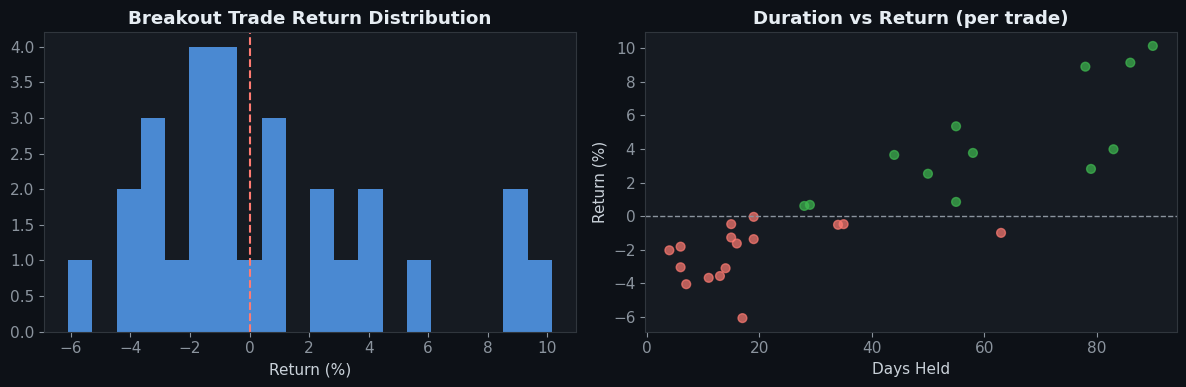

In [13]:
if not result.trade_log.empty:
    tl = result.trade_log
    winners = tl[tl['return_pct'] > 0]
    losers  = tl[tl['return_pct'] <= 0]

    print(f'=== Breakout Trade Statistics ===')
    print(f'Total breakout trades  : {len(tl)}')
    print(f'Successful breakouts   : {len(winners)} ({len(winners)/len(tl)*100:.1f}%)')
    print(f'Failed breakouts       : {len(losers)}  ({len(losers)/len(tl)*100:.1f}%)')
    print(f'Avg win  : {winners["return_pct"].mean():.2f}% over {winners["duration_days"].mean():.1f} days')
    print(f'Avg loss : {losers["return_pct"].mean():.2f}%  over {losers["duration_days"].mean():.1f} days')
    print(f'Win/Loss ratio: {winners["return_pct"].mean() / abs(losers["return_pct"].mean()):.2f}')

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(tl['return_pct'], bins=20, color='#58a6ff', edgecolor='none', alpha=0.8)
    axes[0].axvline(0, color='#ff7b72', linewidth=1.5, linestyle='--')
    axes[0].set_title('Breakout Trade Return Distribution', fontweight='bold')
    axes[0].set_xlabel('Return (%)')

    axes[1].scatter(tl['duration_days'], tl['return_pct'],
                   color=['#3fb950' if r > 0 else '#ff7b72' for r in tl['return_pct']],
                   alpha=0.7, s=40)
    axes[1].axhline(0, color='#8b949e', linewidth=1.0, linestyle='--')
    axes[1].set_title('Duration vs Return (per trade)', fontweight='bold')
    axes[1].set_xlabel('Days Held')
    axes[1].set_ylabel('Return (%)')
    plt.tight_layout()
    plt.show()
else:
    print('No completed trades in log.')

## 13. Interpretation and Conclusions

### How the strategy works
The strategy waits for the NIFTY 50 to close above a fresh 20-day high, with volume above its moving average confirming institutional participation. The exit relies on a tighter 10-day Donchian lower channel or an ATR-based trailing stop, whichever triggers first.

### Breakout anatomy
Breakout strategies classically have **low win rates but high win-to-loss ratios**. A typical successful trade captures a trending move several multiples of the initial risk, while failed breakouts are stopped out quickly. The 60-day holding cap prevents holding through long deteriorations.

### Volume confirmation importance
Requiring volume > 20-day average reduces false breakouts (where price briefly exceeds the channel on thin trading, only to snap back). High-volume breakouts are more likely to reflect genuine shifts in supply-demand balance.

### ADX filter
Breakouts are most reliable when the market is already in a trending state (ADX > 20). In ranging markets (low ADX), breakouts have higher failure rates as prices tend to oscillate around support/resistance rather than persistently exceed them.

### Limitations
1. **Whipsaw risk**: In choppy markets (e.g., 2022 Indian equity market volatility), the strategy may experience multiple consecutive failed breakouts, each incurring entry and exit costs.
2. **Look-ahead-free channel computation**: We use yesterday's channel (shift(1)) at all decision points. This reduces the theoretical win rate slightly vs. a system that uses the current day's range, but it is the only valid approach.
3. **ATR stop calculation**: The ATR stop is set at entry and not updated daily. A dynamic trailing stop (updated each day) would likely improve performance but requires a more complex implementation.
4. **Index only**: This strategy would typically be applied to individual stocks where breakouts are more pronounced and less correlated. Single-index application reduces the opportunity set.

---
*All results computed programmatically from actual data.*